# yambo_nl: silently corrupted frequencies in the runs on bulk LiF

Report for the yambo developers. In several `yambo_nl` runs (frequency loop, `NL_ROLEs` = "w.k") the polarization of
one or more groups of frequencies of the `w` parallelization is wrong, with no error or warning in the report, the
logs or the job output. The runs end normally and the wrong frequencies can be found only by comparing with an
independent calculation. This notebook collects the cases, the size and the shape of the error, the restart tests
and the workaround used.

**Summary**

- The wrong frequencies always belong to one or two groups of the `w` parallelization. Once a group is corrupted, all
  the following frequencies of that group are wrong; the other groups are correct.
- In all the cases but one, the first wrong frequency is the **third** frequency computed by its group (the first two
  are always correct). In the remaining case it is the 13th.
- The error starts at the first time step after the switch-on of the field. Before that, $P(t)$ is identical bit by bit
  to the correct run, numerical noise included. The response is reduced and has a different shape: the projection $c$
  on the correct $P(t)$ is 0.45-0.98 depending on the run and the group (max $|P|$ 52-100% of the correct one). In three
  of the six cases $c$ is the same within 0.01 for all the wrong frequencies of a group (e.g. 0.564 on 37 frequencies,
  case B). It looks as if a fixed part of the k points of the group no longer coupled to the field.
- The error is intermittent: the same input with the same parallelization recomputes the wrong frequencies correctly.
  The correct frequencies are reproducible **bit by bit** across restarts, numbers of nodes, nodes and `NL_CPU`.
- It was seen on the kx12 and kx16 grids (1 and 2 nodes, `NL_CPU` "4.8" and "8.8") and never on kx8. In the 2-node
  runs the job output also contains hundreds of segmentation faults caught by the MXM library, with or without
  corrupted frequencies.
- Workaround: recompute the wrong frequencies by a restart in chunks of at most 2 frequencies per group.

## System, code and inputs

- Code: Lumen 2.1.0 fork of yambo (`yambo_nl`), built with gcc 10.2.1 and OpenMPI 4.0.4 (MXM transport) on the
  ismhpc cluster (nodes with 32 cores and 125 GB, CentOS 7.7). 1 or 2 nodes, 32 MPI tasks per node, 1 OpenMP thread.
- System: bulk LiF, IP approximation with scissor (`GfnQP_E` = 6 eV), bands 3-6 (`NLBands`), Berry phase coupling with
  the fields, `NLintegrator` = INVINT, `NLstep` = 0.01 fs, `NLtime` = 100 fs, `NLDamping` = 0.3 eV.
- SAVE from QE with 8 symmetries, without inversion and time reversal; k grids $8^3$, $12^3$, $16^3$ $\Gamma$-centered
  (100, 294, 648 points in the IBZ). The setup databases were regenerated with Lumen 2.1.0.
- Frequency loop: 155 probe frequencies 10.000-24.919 eV (`NLEnRange` = [10, 25.015625] eV, `NLEnSteps` = 155), or 39
  frequencies (every 4th of them) in the test runs. SIN probe field (`Field1`, 1e3 kW/m$^2$, the frequency is the loop
  variable) and, in the frequency mixing runs (P&p), a SIN pump field (`Field2`, 1.55 eV, 1e6-1.6e7 kW/m$^2$), both
  starting at 0.1 fs.
- Parallelization: `NL_ROLEs` = "w.k", `NL_CPU` = "4.8" on 1 node (4 groups of frequencies, 8 tasks on the k points in
  each group) or "8.8" on 2 nodes. Frequency `i` (0-based) is computed by group `i mod n_groups`, in increasing
  order, so its position in the group is `i // n_groups + 1`.

The input of the kx12 P&p run:

In [1]:
import os, glob, re
import numpy as np
import netCDF4
import matplotlib.pyplot as plt
from mppi import Parsers as P, Optics as O
from mppi.Utilities import Constants as Const

ids = {'sine'  : 'pulse-E1_1e3-nlenrange_10.0-25.016-nlensteps_155-bands_3-6-damp_0.3-sin-nltime_100',
       'Pp'    : 'Pp-Ep_1e3-EP_1e6-PE_1.55-nlenrange_10.0-25.016-nlensteps_155-bands_3-6-damp_0.3-sin-nltime_100',
       'Pp_1.6e7' : 'Pp-Ep_1e3-EP_1.6e7-PE_1.55-nlenrange_10.0-25.113-nlensteps_39-bands_3-6-damp_0.3-sin-nltime_100'}
dirs = {'kx8':'kx8_nb100_NoTr_E100', 'kx12':'kx12_nb100_NoTr_E100', 'kx16':'kx16_nb100_NoTr_E100'}

print(open(os.path.join(dirs['kx12'],ids['Pp']+'.in')).read())

#                                                                     
# $$\                                                                 
# $$ |                                                                
# $$ |     $$\   $$\ $$$$$$\$$$$\   $$$$$$\  $$$$$$$\                 
# $$ |     $$ |  $$ |$$  _$$  _$$\ $$  __$$\ $$  __$$\                
# $$ |     $$ |  $$ |$$ / $$ / $$ |$$$$$$$$ |$$ |  $$ |               
# $$ |     $$ |  $$ |$$ | $$ | $$ |$$   ____|$$ |  $$ |               
# $$$$$$$$\\$$$$$$  |$$ | $$ | $$ |\$$$$$$$\ $$ |  $$ |               
# \________|\______/ \__| \__| \__| \_______|\__|  \__|               
#                                                                     
#                   Fork Lumen 2.1.0                                  
#                   Branch is master                                  
#        MPI+OpenMP+SLK+SLEPC+HDF5_MPI_IO Build                       
#               http://www.lumen-code.org                             
#
nlop

## Comparison of corrupted and correct fragments

Each frequency is written by `yambo_nl` in the fragment `ndb.Nonlinear_fragment_<i+1>`, with $P(t)$, $E_{ext}(t)$ and
$E_{tot}(t)$ on all the 10001 time steps. For each case below the fragments of the wrong run are compared with
the correct ones at the same frequency. The correct fragments come from an independent run of the same input (other
number of nodes) or from the restart that recomputed the frequency. For each frequency:

- `ratio`: $\max_t|P_x^{bad}|/\max_t|P_x^{good}|$;
- `diff`: $\max_t|P_x^{bad}-P_x^{good}|/\max_t|P_x^{good}|$ (0 means identical bit by bit);
- `first`: first time step where the two differ by more than $10^{-6}\max|P_x^{good}|$;
- `c`, `res`: projection $c=\langle P^{bad},P^{good}\rangle/\langle P^{good},P^{good}\rangle$ and relative residual
  $\max|P^{bad}-cP^{good}|/\max|P^{bad}|$ (`res` = 0 if the wrong response is just rescaled);
- `dE`: relative difference of $E_{ext}(t)$ (the fields are always identical).

The cases:

| case | grid | run | nodes | `NL_CPU` | job |
|---|---|---|---|---|---|
| A | kx12 | sine, 155 freq. | 2 (wnode07-08) | 8.8 | original run (good run: same input on 1 node, wnode05); run deleted on 2026-10-12, results below |
| B | kx12 | P&p 1e6, 155 freq. | 1 (wnode07) | 4.8 | original run (good run: same input on 2 nodes, wnode02,05) |
| C | kx12 | P&p 1.6e7, 39 freq. | 1 (wnode02) | 4.8 | original run (good: restart 1a, wnode06) |
| D | kx16 | sine, 155 freq. | 1 (wnode05) | 4.8 | original run (good: chunk repair) |
| E | kx16 | sine, 74 freq. | 1 (wnode04) | 4.8 | restart of D, job 59071 (good: chunk repair) |
| F | kx16 | P&p 1e6, 155 freq. | 1 (wnode04) | 4.8 | original run (good: restart, job 59072, wnode01) |

In the restart E (and in the repairs) the frequencies to recompute keep their group (`i mod 4`), and the position
in the group is the rank among the recomputed frequencies of that group.

In [2]:
def frag(run, i, suffix=''):
    return os.path.join(run,'ndb.Nonlinear_fragment_%d%s'%(i+1,suffix))

def read_frag(path):
    ds = netCDF4.Dataset(path)
    out = {}
    for k in ds.variables:
        for name in ['NL_P','E_ext','E_tot']:
            if k.startswith(name+'_freq'): out[name] = np.array(ds.variables[k][:])
    ds.close()
    return out

def compare(bad_path, good_path):
    b, g = read_frag(bad_path), read_frag(good_path)
    pb, pg = b['NL_P'][0], g['NL_P'][0]
    s = np.abs(pg).max()
    dp = np.abs(pb-pg)
    k = np.nonzero(dp > 1e-6*s)[0]
    c = np.dot(pb,pg)/np.dot(pg,pg)
    return dict(ratio=np.abs(pb).max()/s, diff=dp.max()/s, first=(k[0] if len(k) else -1), c=c,
                res=np.abs(pb-c*pg).max()/np.abs(pb).max(),
                dE=np.abs(b['E_ext']-g['E_ext']).max()/np.abs(g['E_ext']).max())

def kx16_restart_list(kind):
    # frequencies of the groups 1 and 2 recomputed by the kx16 restarts (from the first wrong one of each group)
    first = {'sine':(9,10), 'Pp':(9,50)}[kind]
    return sorted(list(range(first[0],155,4))+list(range(first[1],155,4)))

# bad: (folder of the wrong run, suffix of its fragments); good: folder of the correct fragments;
# computed: frequencies computed by the job of the wrong run (in increasing order)
r16s, r16p = os.path.join(dirs['kx16'],ids['sine']), os.path.join(dirs['kx16'],ids['Pp'])
cases = {
 'B': dict(bad=(os.path.join(dirs['kx12'],ids['Pp']+'_corrupted'),''), good=os.path.join(dirs['kx12'],ids['Pp']),
           n_groups=4, computed=list(range(155))),
 'C': dict(bad=(os.path.join(dirs['kx12'],ids['Pp_1.6e7']),'_corrupted'), good=os.path.join(dirs['kx12'],ids['Pp_1.6e7']),
           n_groups=4, computed=list(range(39))),
 'D': dict(bad=(r16s,'_corrupted'), good=r16s, n_groups=4, computed=list(range(155))),
 'E': dict(bad=(r16s,'_corrupted_repair1'), good=r16s, n_groups=4, computed=kx16_restart_list('sine')),
 'F': dict(bad=(r16p,'_corrupted'), good=r16p, n_groups=4, computed=list(range(155))),
}

In [3]:
def analyse_case(case, done=None):
    # comparison at all the frequencies computed by the job; a frequency whose fragment was not renamed is the same file
    # in the two runs (correct by construction). done: frequencies actually computed (restart E: cancelled job)
    folder, suf = case['bad']
    ng = case['n_groups']
    pos, rows = {}, {}
    for i in case['computed']:
        pos[i] = sum(1 for j in case['computed'] if j%ng == i%ng and j <= i)
    for i in case['computed']:
        b = frag(folder,i,suf)
        if not os.path.isfile(b):
            if suf and os.path.isfile(frag(folder,i)) and (done is None or i in done):
                rows[i] = dict(ratio=1., diff=0., first=-1, c=1., res=0., dE=0., same_file=True)
            continue
        if not os.path.isfile(frag(case['good'],i)): continue
        rows[i] = compare(b,frag(case['good'],i))
        rows[i]['same_file'] = False
    for i in rows: rows[i].update(group=i%ng, pos=pos[i])
    return rows

def summary(name, rows, tol=1e-6):
    bad = [i for i in sorted(rows) if rows[i]['diff'] > tol]
    good = [i for i in sorted(rows) if rows[i]['diff'] <= tol]
    ident = [i for i in good if not rows[i]['same_file']]
    print('case %s: %d frequencies compared, %d wrong, %d correct (%d compared bit by bit, all identical: %s)'%(
          name,len(rows),len(bad),len(good),len(ident),all(rows[i]['diff'] == 0 for i in ident)))
    for g in sorted(set(rows[i]['group'] for i in bad)):
        bg = [i for i in bad if rows[i]['group'] == g]
        gg = [i for i in good if rows[i]['group'] == g and i > bg[0]]
        print('   group %d: first wrong index %d (position %d in the group), %d wrong, correct after it: %s'%(
              g,bg[0],rows[bg[0]]['pos'],len(bg),gg if gg else 'none'))
        v = lambda k : np.array([rows[i][k] for i in bg])
        print('            ratio %.3f-%.3f  c %.3f-%.3f  res %.2f-%.2f  first time step %s  dE max %.1e'%(
              v('ratio').min(),v('ratio').max(),v('c').min(),v('c').max(),v('res').min(),v('res').max(),
              sorted(set(v('first'))),v('dE').max()))
    return bad

# job 59071 (restart E) was cancelled: the frequencies it computed are the ones renamed _corrupted_repair1 and the
# first two of each group (9, 13 and 10, 14), which were correct
done_E = set(i for i in cases['E']['computed'] if os.path.isfile(frag(r16s,i,'_corrupted_repair1'))) | {9,13,10,14}
results, wrong = {}, {}
for name, case in cases.items():
    results[name] = analyse_case(case, done=(done_E if name == 'E' else None))
    wrong[name] = summary(name,results[name])

case B: 155 frequencies compared, 37 wrong, 118 correct (118 compared bit by bit, all identical: True)
   group 2: first wrong index 10 (position 3 in the group), 37 wrong, correct after it: none
            ratio 0.746-0.807  c 0.561-0.568  res 0.28-0.30  first time step [np.int64(12)]  dE max 0.0e+00


case C: 39 frequencies compared, 8 wrong, 31 correct (0 compared bit by bit, all identical: True)
   group 2: first wrong index 10 (position 3 in the group), 8 wrong, correct after it: none
            ratio 0.812-0.834  c 0.659-0.659  res 0.21-0.21  first time step [np.int64(12)]  dE max 0.0e+00


case D: 155 frequencies compared, 74 wrong, 81 correct (0 compared bit by bit, all identical: True)
   group 1: first wrong index 9 (position 3 in the group), 37 wrong, correct after it: none
            ratio 0.766-0.908  c 0.741-0.840  res 0.06-0.18  first time step [np.int64(12)]  dE max 0.0e+00
   group 2: first wrong index 10 (position 3 in the group), 37 wrong, correct after it: none
            ratio 0.905-1.011  c 0.877-0.978  res 0.03-0.16  first time step [np.int64(12)]  dE max 0.0e+00


case E: 30 frequencies compared, 26 wrong, 4 correct (0 compared bit by bit, all identical: True)
   group 1: first wrong index 17 (position 3 in the group), 13 wrong, correct after it: none
            ratio 0.890-0.934  c 0.858-0.897  res 0.05-0.11  first time step [np.int64(12)]  dE max 0.0e+00
   group 2: first wrong index 18 (position 3 in the group), 13 wrong, correct after it: none
            ratio 0.893-0.938  c 0.866-0.902  res 0.05-0.11  first time step [np.int64(12)]  dE max 0.0e+00


case F: 155 frequencies compared, 64 wrong, 91 correct (0 compared bit by bit, all identical: True)
   group 1: first wrong index 9 (position 3 in the group), 37 wrong, correct after it: none
            ratio 0.937-0.983  c 0.940-0.942  res 0.04-0.04  first time step [np.int64(12)]  dE max 0.0e+00
   group 2: first wrong index 50 (position 13 in the group), 27 wrong, correct after it: none
            ratio 0.909-0.935  c 0.855-0.857  res 0.08-0.09  first time step [np.int64(12)]  dE max 0.0e+00


**Notes on the table.** In all the cases the wrong frequencies start at the time step after the switch-on of the
field. $E_{ext}$ is the same and $P(t)$ is the same bit by bit up to that step (see the figure below). The correct
frequencies of the wrong runs are identical bit by bit to the ones of the independent runs, also with another number
of nodes (A, B) or another node. Case A (run deleted on 2026-10-12 to free space; result of the same comparison made before): 36 wrong frequencies
of 155, groups 1 and 2 of 8 from their 3rd frequency (indices 17 and 18), max $|P|$ 52-92% of the correct one, $c$
0.45-0.66, `res` 0.24-0.39, first wrong time step 12, the 119 correct frequencies identical bit by bit to the 1-node run.
In case F (kx16 P&p) the 2nd group goes wrong at its 13th frequency, the only case
not at the 3rd one. Once a group is wrong, it never recovers: all its following frequencies are wrong, also when
the error is small (case F, group 1: max $|P|$ 94-98% of the correct one).

## Shape of the error

Top: the linear susceptibility $\chi_{(1,0)}$ of the kx12 P&p run (case B), extracted with the harmonic analysis of
MPPI, in the corrupted run and in the correct one, compared with the linear response of a delta kick run on the
same grid. Bottom left: ratio of the $|\chi|$ of the two runs per frequency. Bottom right: $P_x(t)$ at a wrong
frequency.

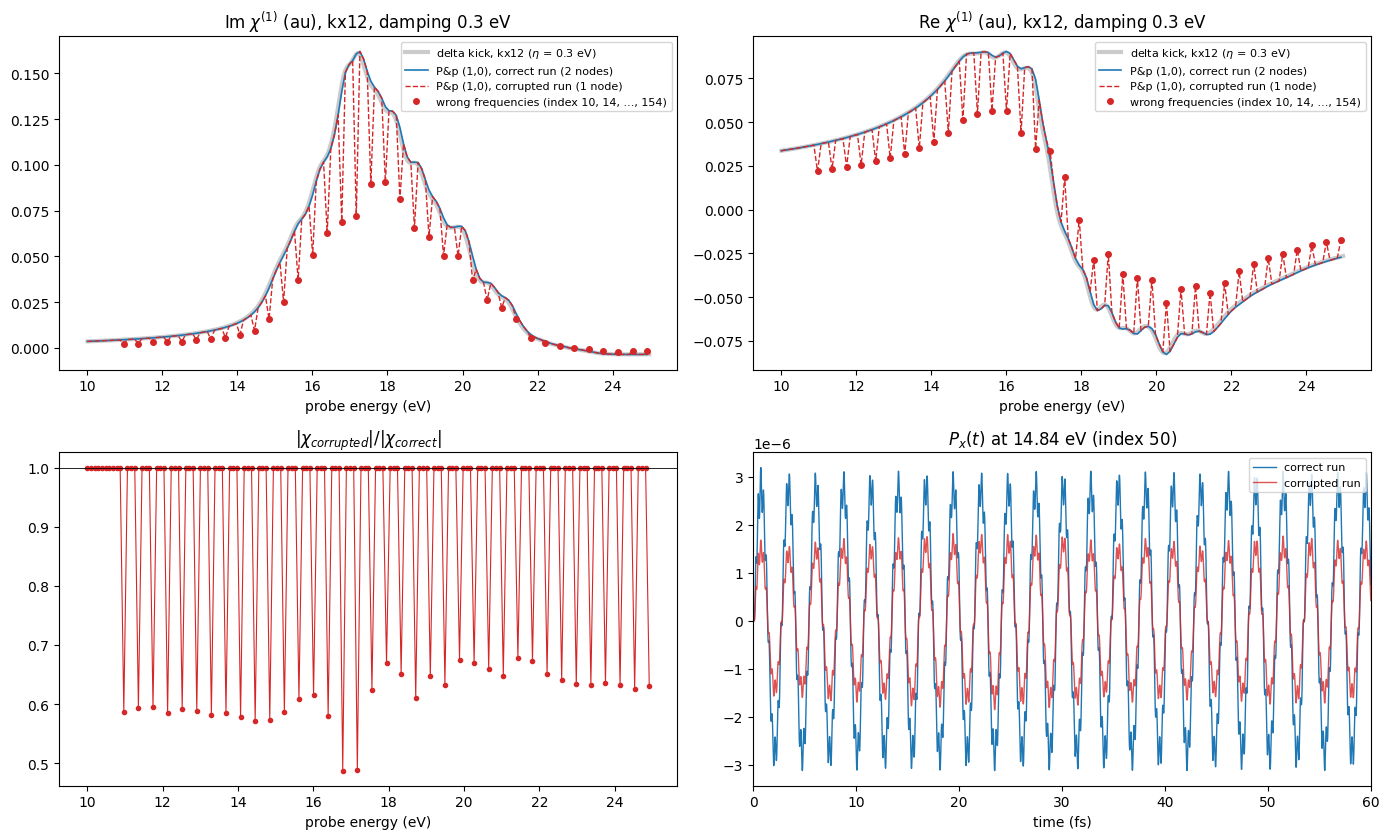

In [4]:
kx12 = dirs['kx12']
db = lambda r: P.YamboNLDBParser(os.path.join(kx12,r,'ndb.Nonlinear'),verbose=False)
dg, dc = db(ids['Pp']), db(ids['Pp']+'_corrupted')
f = np.array([e['freq_range'][0] for e in dg.Efield])*Const.HaToeV
cg = O.Xn_frequency_mixing(dg,X_order=(1,2),verbose=False).compute_Xn()[0][(1,0)]
cc = O.Xn_frequency_mixing(dc,X_order=(1,2),verbose=False).compute_Xn()[0][(1,0)]
dd = db('lresponse-bands_3-6-delta')
en, eps = O.Linear_Response(np.array(dd.IO_TIME_points),dd.Polarization[0],dd.Efield[0],eta=0.3)
cd = (eps-1)/(4*np.pi)
s = (en > 10) & (en < 25)
bad = np.array(wrong['B'])

fig, ax = plt.subplots(2,2,figsize=(14,8.5))
for col, (part, lab) in enumerate([(np.imag,'Im'),(np.real,'Re')]):
    a = ax[0,col]
    a.plot(en[s],part(cd[s]),color='0.6',lw=3,alpha=0.5,label='delta kick, kx12 ($\\eta$ = 0.3 eV)')
    a.plot(f,part(cg),'C0-',lw=1.2,label='P&p (1,0), correct run (2 nodes)')
    a.plot(f,part(cc),'C3--',lw=1,label='P&p (1,0), corrupted run (1 node)')
    a.plot(f[bad],part(cc[bad]),'C3o',ms=4,label='wrong frequencies (index 10, 14, ..., 154)')
    a.set_title('%s $\\chi^{(1)}$ (au), kx12, damping 0.3 eV'%lab)
    a.set_xlabel('probe energy (eV)')
    a.legend(fontsize=8)
a = ax[1,0]
a.plot(f,np.abs(cc)/np.abs(cg),'C3.-',lw=0.8)
a.axhline(1,color='k',lw=0.6)
a.set_title('$|\\chi_{corrupted}|/|\\chi_{correct}|$')
a.set_xlabel('probe energy (eV)')
i = 50
t = np.array(dg.IO_TIME_points)/Const.FsToAu
a = ax[1,1]
a.plot(t,dg.Polarization[i][0],'C0',lw=1,label='correct run')
a.plot(t,dc.Polarization[i][0],'C3',lw=1,alpha=0.8,label='corrupted run')
a.set_title('$P_x(t)$ at %.2f eV (index %d)'%(f[i],i))
a.set_xlabel('time (fs)')
a.set_xlim(0,60)
a.legend(fontsize=8)
plt.tight_layout()
plt.show()

First time steps of $P_x(t)$ at the same frequency. The fields start at `Tstart` = 0.1 fs (step 10), and $E_{ext}$ is
nonzero from step 11. Before that, $P$ is numerical noise ($\sim10^{-19}$ au) and it is identical bit by bit in the
two runs. So the ground state and its polarization are the same, and only the response to the field differs.

 step  t (fs)   E_ext,x (au)     P_x correct       P_x corrupted     ratio
    8   0.08  -0.000000e+00  -4.347288e-19  -4.347288e-19  1.0000
    9   0.09  -0.000000e+00  -5.848458e-19  -5.848458e-19  1.0000
   10   0.10  -0.000000e+00   6.357087e-19   6.357087e-19  1.0000
   11   0.11   3.654577e-06   5.141447e-19   5.141447e-19  1.0000
   12   0.12   7.264852e-06   3.111825e-09   1.324012e-09  0.4255
   13   0.13   1.078869e-05   1.525603e-08   7.253354e-09  0.4754
   14   0.14   1.418817e-05   4.149993e-08   2.060651e-08  0.4965
   15   0.15   1.743145e-05   8.561234e-08   4.349291e-08  0.5080
   16   0.16   2.049427e-05   1.497326e-07   7.713089e-08  0.5151
   17   0.17   2.336113e-05   2.341812e-07   1.217447e-07  0.5199


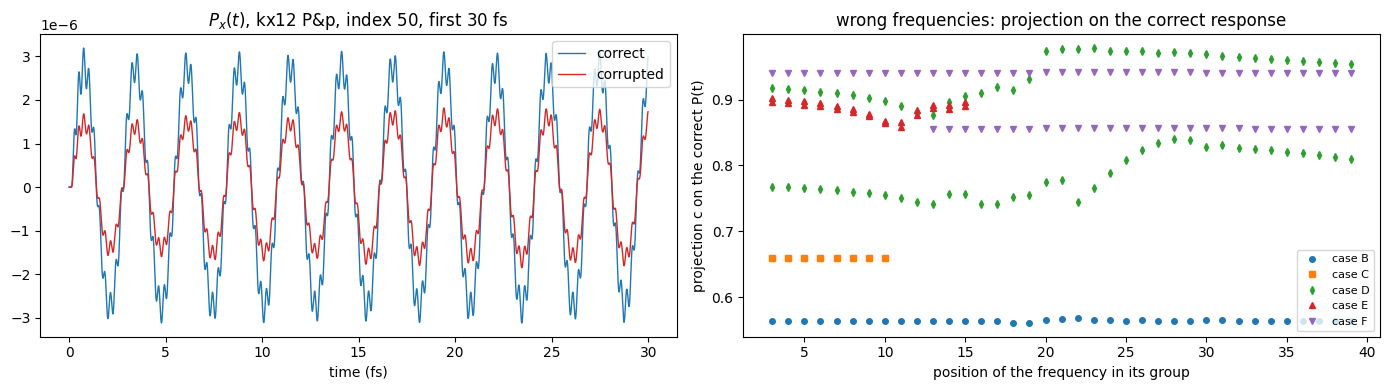

In [5]:
pg = read_frag(frag(os.path.join(kx12,ids['Pp']),50))
pc = read_frag(frag(os.path.join(kx12,ids['Pp']+'_corrupted'),50))
print(' step  t (fs)   E_ext,x (au)     P_x correct       P_x corrupted     ratio')
for k in range(8,18):
    e = pg['E_ext'][0,k,0]
    a, b = pg['NL_P'][0,k], pc['NL_P'][0,k]
    print('%5d  %5.2f  % .6e  % .6e  % .6e  %.4f'%(k,k*0.01,e,a,b,b/a))

fig, ax = plt.subplots(1,2,figsize=(14,4))
n = 3000
tt = np.arange(n)*0.01
ax[0].plot(tt,pg['NL_P'][0,:n],'C0',lw=1,label='correct')
ax[0].plot(tt,pc['NL_P'][0,:n],'C3',lw=1,label='corrupted')
ax[0].set_xlabel('time (fs)')
ax[0].set_title('$P_x(t)$, kx12 P&p, index 50, first 30 fs')
ax[0].legend()
r = np.array([[results[c][i]['c'] for i in wrong[c]] for c in ['B']])[0]
for c, m in zip(cases,'osd^vx'):
    if wrong[c]:
        ax[1].plot([results[c][i]['pos'] for i in wrong[c]],[results[c][i]['c'] for i in wrong[c]],m,ms=4,label='case %s'%c)
ax[1].set_xlabel('position of the frequency in its group')
ax[1].set_ylabel('projection c on the correct P(t)')
ax[1].set_title('wrong frequencies: projection on the correct response')
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Restart tests

`yambo_nl` recomputes only the frequencies whose fragment is missing (`NL_start_and_restart`). So the wrong fragments
are renamed and the same input is run again in the same folder. On the kx12 P&p run with pump 1.6e7 kW/m$^2$
(case C, 8 wrong frequencies, indices 10, 14, ..., 38 of group 2):

- **1a**: restart with the same `NL_CPU` = "4.8" (wnode06). Group 2 recomputes the same 8 frequencies, now as its
  first ones, and they are all correct ($\chi_{(1,0)}$ equal to $\chi^{(1)}$ of an independent sine run within
  $10^{-4}$-$10^{-3}$, as at the other frequencies).
- **1b**: the fragments of 1a are renamed (`_restart_NL_CPU_4.8`) and the 8 frequencies are recomputed with `NL_CPU` =
  "1.32" (a single group, all the 32 tasks on the k points). The results are identical bit by bit to the ones of 1a.

So the correct results are exactly reproducible with different parallelizations of the k points, and the error is
not tied to particular frequencies or to a group.

In [6]:
run_c = os.path.join(kx12,ids['Pp_1.6e7'])
print(' index   1a vs 1b: max|dP|/max|P|    original (wrong) vs 1b: ratio')
for i in range(10,39,4):
    a = compare(frag(run_c,i,'_restart_NL_CPU_4.8'),frag(run_c,i))
    b = compare(frag(run_c,i,'_corrupted'),frag(run_c,i))
    print('  %3d          %.1e                      %.3f'%(i,a['diff'],b['ratio']))

 index   1a vs 1b: max|dP|/max|P|    original (wrong) vs 1b: ratio
   10          0.0e+00                      0.812


   14          0.0e+00                      0.816
   18          0.0e+00                      0.812
   22          0.0e+00                      0.826


   26          0.0e+00                      0.834
   30          0.0e+00                      0.832
   34          0.0e+00                      0.818


   38          0.0e+00                      0.818


## Repair of the kx16 runs and the "third frequency" pattern

The kx16 runs (about 14 h per run on one node) were repaired by restarts with `NL_CPU` = "4.8":

- P&p (case F): restart of the 64 frequencies of groups 1 and 2 from the first wrong one (job 59072, wnode01).
- sine: the restart of the 74 frequencies (case E, job 59071, wnode04) gave correct values for the first two
  frequencies of each group (9, 13 and 10, 14) and wrong ones again from the third (17 and 18). The job was
  cancelled, and the remaining 70 frequencies were recomputed in jobs of 4 frequencies (2 per group). Before each job
  the fragments of the other missing frequencies are replaced by placeholders, so that yambo computes only the chunk.
  None of the chunks had a wrong frequency (log below: max $|P|$ over the interpolation of the correct neighbours).

In [7]:
log = os.path.expanduser('~/tmp_claude/chunk_repair_kx16_sine.log')
for l in open(log):
    if re.match(r'\d\d/\d\d \d\d:\d\d pass',l): print(l.rstrip())

09/10 17:08 pass 0: 70 frequencies to be computed in 18 chunks
09/10 17:08 pass 0 chunk 0: computing [17, 18, 21, 22] (66 placeholders)
09/10 17:42 pass 0 chunk 0: 17:1.001 18:1.000 21:1.000 22:1.000, missing []
09/10 17:42 pass 0 chunk 1: computing [25, 26, 29, 30] (62 placeholders)
09/10 18:08 pass 0 chunk 1: 25:1.002 26:1.002 29:0.997 30:0.998, missing []
09/10 18:08 pass 0 chunk 2: computing [33, 34, 37, 38] (58 placeholders)
09/10 18:34 pass 0 chunk 2: 33:1.002 34:1.002 37:0.998 38:0.995, missing []
09/10 18:34 pass 0 chunk 3: computing [41, 42, 45, 46] (54 placeholders)
09/10 19:19 pass 0 chunk 3: 41:0.998 42:1.000 45:0.996 46:0.995, missing []
09/10 19:19 pass 0 chunk 4: computing [49, 50, 53, 54] (50 placeholders)
09/10 19:45 pass 0 chunk 4: 49:1.004 50:1.003 53:0.998 54:0.996, missing []
09/10 19:45 pass 0 chunk 5: computing [57, 58, 61, 62] (46 placeholders)
09/10 20:11 pass 0 chunk 5: 57:0.998 58:1.001 61:0.996 62:1.001, missing []
09/10 20:11 pass 0 chunk 6: computing [65, 

Position in its group of the first wrong frequency, for every corrupted group:

In [8]:
print('case  group  first wrong index  position in the group')
for c in cases:
    for g in sorted(set(results[c][i]['group'] for i in wrong[c])):
        i0 = [i for i in wrong[c] if results[c][i]['group'] == g][0]
        print('  %s     %d          %3d                 %d'%(c,g,i0,results[c][i0]['pos']))

case  group  first wrong index  position in the group
  B     2           10                 3
  C     2           10                 3
  D     1            9                 3
  D     2           10                 3
  E     1           17                 3
  E     2           18                 3
  F     1            9                 3
  F     2           50                 13


## Segmentation faults of the MXM library in the 2-node runs

All the runs on 2 nodes have hundreds of segmentation faults in the job output, caught by the MXM library (with
400 MB core dumps). The runs still end normally and write all the fragments. The kx8 2-node runs are identical bit
by bit to the 1-node runs, so the segfaults do not always corrupt the results. The 1-node runs never show them,
but they can be corrupted (cases B-F).

In [9]:
jobs = sorted(glob.glob(os.path.join('kx*_nb100_NoTr_E100','job_*damp_0.3*.out'))+
              glob.glob(os.path.join('kx*_nb100_NoTr_E100','*_backup_orig','job_*.out')))
print('segfaults  nodes          job output')
for j in jobs:
    txt = open(j,errors='replace').read()
    nodes = re.findall(r'Job nodelist (\S+)',txt)
    print('%6d     %-14s %s'%(txt.count('Caught signal 11'),nodes[0] if nodes else '?',
          j.replace('nlenrange_10.0-25.016-nlensteps_155-bands_3-6-damp_0.3-sin-nltime_100','...')))
ex = os.path.join(kx12,'job_%s_corrupted.out'%ids['sine'])
print('\nexample (%s):'%os.path.basename(ex))
print(''.join([l for l in open(ex,errors='replace') if 'Caught signal' in l][:3]))

segfaults  nodes          job output
     0     wnode02        kx12_nb100_NoTr_E100/Pp-Ep_1e3-EP_1.6e7-PE_1.55-nlenrange_10.0-25.113-nlensteps_39-bands_3-6-damp_0.3-sin-nltime_100_backup_orig/job_Pp-Ep_1e3-EP_1.6e7-PE_1.55-nlenrange_10.0-25.113-nlensteps_39-bands_3-6-damp_0.3-sin-nltime_100.out
     0     wnode02        kx12_nb100_NoTr_E100/job_Pp-Ep_1e3-EP_1.6e7-PE_1.55-nlenrange_10.0-25.113-nlensteps_39-bands_3-6-damp_0.3-sin-nltime_100.out
  1946     wnode[02,05]   kx12_nb100_NoTr_E100/job_Pp-Ep_1e3-EP_1e6-PE_1.55-....out
     0     wnode07        kx12_nb100_NoTr_E100/job_Pp-Ep_1e3-EP_1e6-PE_1.55-..._corrupted.out
     0     wnode11        kx12_nb100_NoTr_E100/job_Pp-Ep_1e3-EP_4e6-PE_1.55-....out
     0     wnode05        kx12_nb100_NoTr_E100/job_pulse-E1_1e3-....out
  1548     wnode[07-08]   kx12_nb100_NoTr_E100/job_pulse-E1_1e3-..._corrupted.out
     0     wnode04        kx16_nb100_NoTr_E100/Pp-Ep_1e3-EP_1e6-PE_1.55-..._backup_orig/job_Pp-Ep_1e3-EP_1e6-PE_1.55-....out
     0     w

     0     wnode05        kx16_nb100_NoTr_E100/pulse-E1_1e3-..._backup_orig/job_pulse-E1_1e3-....out
     0     wnode11        kx8_nb100_NoTr_E100/job_Pp-Ep_1e3-EP_1e6-PE_1.55-....out


  1478     wnode[02,07]   kx8_nb100_NoTr_E100/job_Pp-Ep_1e3-EP_1e6-PE_1.55-..._2nodes.out


     0     wnode02        kx8_nb100_NoTr_E100/job_pulse-E1_1e3-....out


  1631     wnode[01-02]   kx8_nb100_NoTr_E100/job_pulse-E1_1e3-..._2nodes.out

example (job_pulse-E1_1e3-nlenrange_10.0-25.016-nlensteps_155-bands_3-6-damp_0.3-sin-nltime_100_corrupted.out):
[wnode07:32290:0] Caught signal 11 (Segmentation fault)
[wnode07:32285:0] Caught signal 11 (Segmentation fault)
[wnode07:32286:0] Caught signal 11 (Segmentation fault)



## Questions for the developers

1. The error starts at the first time step with the field, the ground state polarization is identical, and the
   projection on the correct response is almost the same for all the wrong frequencies of a run. That looks like a
   fixed subset of k points (or of their neighbours in the Berry phase finite differences) losing the coupling with the
   field. Which data of a `w` group are set up once and reused across the frequencies (e.g. the overlaps $\langle u_k
   |u_{k+\Delta k}\rangle$ or the neighbour wavefunctions exchanged between the k tasks), and could they be freed or
   overwritten after the second frequency?
2. Why the **third** frequency of a group? Is anything allocated, reset or communicated differently from the third
   frequency on (e.g. a buffer reused after two cycles, an I/O of the fragments that overlaps the next frequency)?
3. The error was seen only on kx12 (294 IBZ points) and kx16 (648 points), never on kx8 (100 points), always with
   8 tasks on the k points per group. Is there a known problem with the k distribution when the k points per task
   are not a divisor of the IBZ points (294/8, 648/8 vs 100/8)?
4. The MXM segfaults on 2 nodes: known problem of `yambo_nl` with OpenMPI 4 + MXM?

A simple check that would catch the problem in yambo: compare the norm of $P(t)$ (or the dipole sum) after the first
step with the field between the groups, or a checksum of the k-dependent data at the start of each frequency.